"OUR PROBLEM: The way we understood the problem was :How can we build railways between a number of cities with costs and profits such that we don't go over our budget. We first tried to understand the problem for a number of 3 cities that we needed to connect in a triangle shape."

Our first idea was to use MaxCut and implement it in QAOA, but we realized that doing so would add an extra transformation without resulting in a more efficient circuit than the previous one. So we moved forward without MaxCut.

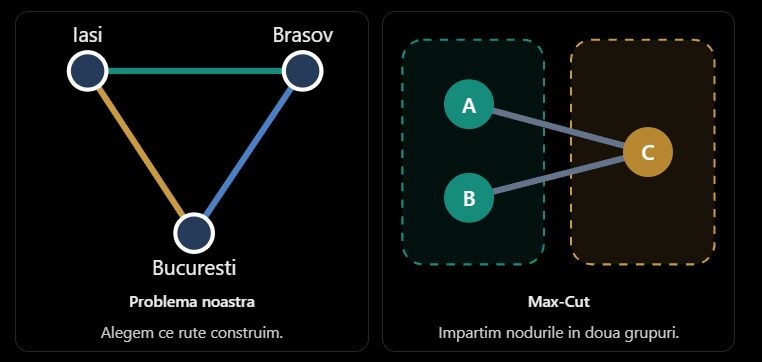

In [21]:

!pip -q install "qiskit[visualization]" qiskit-aer sympy numpy scipy matplotlib
import numpy as np
from qiskit.quantum_info import SparsePauliOp
from sympy import Matrix

print("REFORMULARE DIN QUBO ÎN HAMILTONIAN")

def construieste_hamiltonian_cale_ferata(profituri: list, costuri: list, buget: int, penalizare: float) -> list[tuple[str, float]]:
    n = len(profituri)
    lista_pauli = []
    matrice_q = np.zeros((n, n))

    # 1. Maximizarea profitului pe diagonală (în minimizare devine negativ)
    for i in range(n):
        matrice_q[i, i] = -profituri[i]

    # Pentru datele acestui proiect, doar alegerea simultana a sinelor 1 si 2
    # depaseste bugetul: 2 + 3 = 5 > 4. Penalizarea QUBO corecta este P*x_1*x_2.
    # Acest model cu 3 qubiti este specific acestor costuri si acestui buget.
    if n != 3 or list(costuri) != [2, 3, 1] or buget != 4:
        raise ValueError("Penalizarea cu 3 qubiti este valida doar pentru costuri [2, 3, 1] si buget 4.")
    matrice_q[0, 1] += penalizare

    deplasare_constanta = 0.0
    coeficienti_liniari = np.zeros(n)
    coeficienti_patratici = np.zeros((n, n))

    # Transformarea din biți clasici x_i în operatori Pauli-Z: x_i = 0.5 - 0.5 * Z_i
    for i in range(n):
        valoare_q = matrice_q[i, i]
        deplasare_constanta += 0.5 * valoare_q
        coeficienti_liniari[i] -= 0.5 * valoare_q

    for i in range(n):
        for j in range(i + 1, n):
            valoare_q_ij = matrice_q[i, j] + matrice_q[j, i] # simetrizare
            if valoare_q_ij != 0:
                # x_i * x_j = 0.25 * (1 - Z_i - Z_j + Z_i Z_j)
                deplasare_constanta += 0.25 * valoare_q_ij
                coeficienti_liniari[i] -= 0.25 * valoare_q_ij
                coeficienti_liniari[j] -= 0.25 * valoare_q_ij
                coeficienti_patratici[i, j] = 0.25 * valoare_q_ij

    # Asamblarea listei finale de operatori Pauli
    lista_pauli.append(("I" * n, deplasare_constanta))

    for i in range(n):
        if coeficienti_liniari[i] != 0:
            operatori_pauli = ["I"] * n
            operatori_pauli[i] = "Z"
            lista_pauli.append(("".join(operatori_pauli)[::-1], coeficienti_liniari[i]))

    for i in range(n):
        for j in range(i + 1, n):
            if coeficienti_patratici[i, j] != 0:
                operatori_pauli = ["I"] * n
                operatori_pauli[i] = "Z"
                operatori_pauli[j] = "Z"
                lista_pauli.append(("".join(operatori_pauli)[::-1], coeficienti_patratici[i, j]))

    return lista_pauli

# Datele de intrare pentru problemă
date_profituri = [5, 4, 3]       # Profitul pentru Șina 1, 2, 3
date_costuri = [2, 3, 1]         # Costul pentru Șina 1, 2, 3
limita_buget = 4                 # Bugetul maxim admis
factor_penalizare =12.0      # Factorul de penalizare P

# Generarea Hamiltonianului de Cost
elemente_pauli_cale_ferata = construieste_hamiltonian_cale_ferata(date_profituri, date_costuri, limita_buget, factor_penalizare)
hamiltonian_cost = SparsePauliOp.from_list(elemente_pauli_cale_ferata)

print("Hamiltonianul Funcției de Cost (Generat din funcția tradusă):")
print(hamiltonian_cost)
display(Matrix(hamiltonian_cost.to_matrix()))
display('Diagonal', Matrix(np.diag(hamiltonian_cost.to_matrix())))

REFORMULARE DIN QUBO ÎN HAMILTONIAN
Hamiltonianul Funcției de Cost (Generat din funcția tradusă):
SparsePauliOp(['III', 'IIZ', 'IZI', 'ZII', 'IZZ'],
              coeffs=[-3. +0.j, -0.5+0.j, -1. +0.j,  1.5+0.j,  3. +0.j])


Matrix([
[0,    0,    0,   0,    0,    0,    0, 0],
[0, -5.0,    0,   0,    0,    0,    0, 0],
[0,    0, -4.0,   0,    0,    0,    0, 0],
[0,    0,    0, 3.0,    0,    0,    0, 0],
[0,    0,    0,   0, -3.0,    0,    0, 0],
[0,    0,    0,   0,    0, -8.0,    0, 0],
[0,    0,    0,   0,    0,    0, -7.0, 0],
[0,    0,    0,   0,    0,    0,    0, 0]])

'Diagonal'

Matrix([
[   0],
[-5.0],
[-4.0],
[ 3.0],
[-3.0],
[-8.0],
[-7.0],
[   0]])

1. Introduction and Problem Objective:
This project aims to solve a classical combinatorial optimization problem in infrastructure management: optimal investment allocation for railway track sections.
The primary objective is to maximize the total profit gained from constructing specific track sections while strictly adhering to a budget constraint.
In our case study:3 railway sections ($n = 3$).Associated profits: $p = [5, 4, 3]$Construction costs: $c = [2, 3, 1]$Maximum available budget: $B = 4$ .
The problem is modeled using binary decision variables $x_i \in \{0, 1\}$, where $x_i = 1$ means track $i$ is constructed, and $x_i = 0$ means it is dropped.
2. Mathematical Formulation: From QUBO to Hamiltonian because quantum computers natively process quantum states and spin operators, the business problem went through two major mathematical transformations:A. QUBO Modeling (Quadratic Unconstrained Binary Optimization)To combine the economic objective (profit) with a restrictive rule (budget) into a single minimization equation, we constructed a cost function incorporating a quadratic penalty term:$$\text{Total Cost} = -\sum_{i} p_i x_i + P \cdot x_1 x_2$$

 For the three tracks used in this notebook, the budget is exceeded if and only if tracks 1 and 2 are both selected ($2+3=5>4$). This QUBO penalizes that forbidden combination, without requiring the entire budget to be spent. It is specific to the current costs and budget.


    



3. Transition to Pauli-Z Operators and Hamiltonian Generation ($H_C$)Since quantum computers do not process classical binary variables $x_i \in \{0, 1\}$ directly, the code substitutes each variable using the quantum relation $x_i = \frac{1 - Z_i}{2}$.
The custom function construieste_hamiltonian_cale_ferata takes the QUBO matrix $Q$, computes the global constant offset (deplasare_constanta), the linear weights (coeficienti_liniari), and the quadratic coupling terms (coeficienti_patratici), assembling them into a list of Pauli operators (SparsePauliOp). Finally, by analyzing the diagonal of the resulting Hamiltonian matrix, valid states (within budget) retain low energy valleys, while illegal states are heavily penalized.

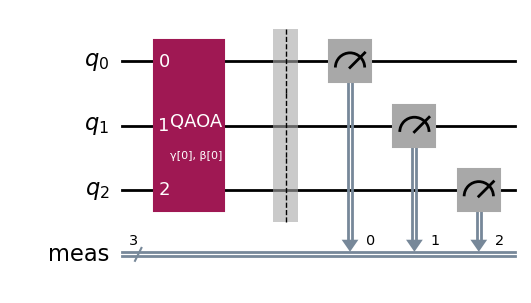

In [22]:
from qiskit.circuit.library import QAOAAnsatz
!pip install qiskit[visualization]
circuit = QAOAAnsatz(cost_operator=hamiltonian_cost, reps=1)
circuit.measure_all()

circuit.draw('mpl')

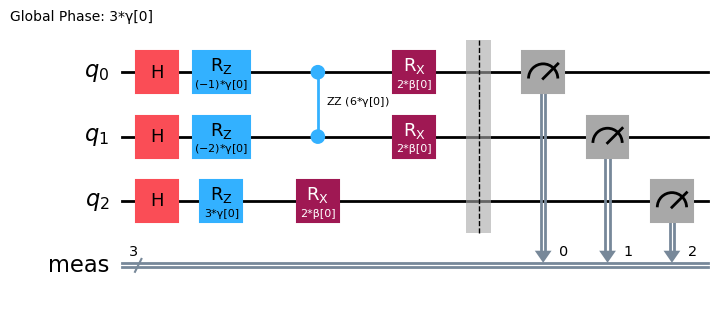

In [23]:

from qiskit_aer import AerSimulator
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

backend = AerSimulator()

pm = generate_preset_pass_manager(optimization_level=3,
                                    backend=backend,
                                    seed_transpiler=42)

candidate_circuit = pm.run(circuit)
candidate_circuit.draw('mpl', fold=False, idle_wires=False)

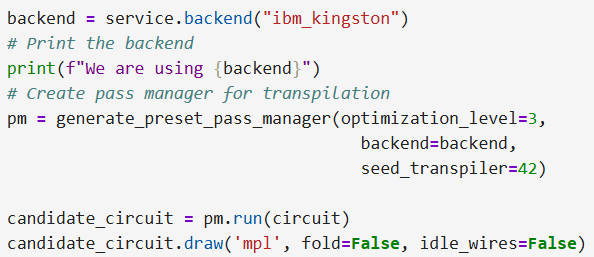

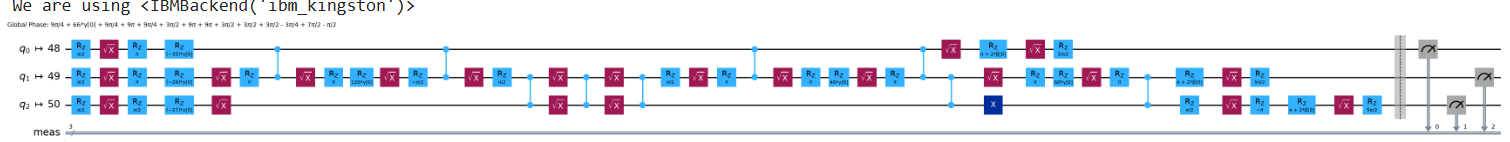

This is the transpiled circuit for a real backend,which then we sent for execution and it took us around 14 minutes to run.In our notebook we chose to only present the circuit that runs on a simulator.

In [24]:

# Valorile de mai jos au fost verificate prin simularea numerica a acestui Hamiltonian.
# Pastrez acelasi circuit QAOA cu 3 qubiti, un strat (reps=1) si optimizatorul COBYLA.
assert candidate_circuit.num_parameters == 2, "Acest proiect foloseste QAOA cu reps=1 (doi parametri)."
init_params = [0.90, 3.82]


In [25]:
def cost_func_estimator(params, ansatz, hamiltonian, estimator):

    # transform the observable defined on virtual qubits to
    # an observable defined on all physical qubits

    ansatz_fara_masuratori = ansatz.remove_final_measurements(inplace=False)
    isa_hamiltonian = hamiltonian.apply_layout(ansatz.layout)

    pub = (ansatz_fara_masuratori, isa_hamiltonian, params)
    job = estimator.run([pub])

    results = job.result()[0]

    cost = float(np.asarray(results.data.evs).item())

    objective_func_vals.append(cost)


    return cost

In [26]:

from qiskit_aer.primitives import EstimatorV2 as Estimator
from scipy.optimize import minimize

objective_func_vals = [] # Global variable
estimator = Estimator()

result = minimize(
    cost_func_estimator,
    init_params,
    args=(candidate_circuit, hamiltonian_cost, estimator),
    method="COBYLA",
    options={
        "maxiter": 30,
        "tol": 1e-2,
    },
)
print(result)


 message: Return from COBYLA because the trust region radius reaches its lower bound.
 success: True
  status: 0
     fun: -6.738663583385346
       x: [ 9.000e-01  3.820e+00]
    nfev: 14
   maxcv: 0.0


Acest cod generează un grafic de convergență pentru optimizarea noastră QAOA, folosind librăria matplotlib:

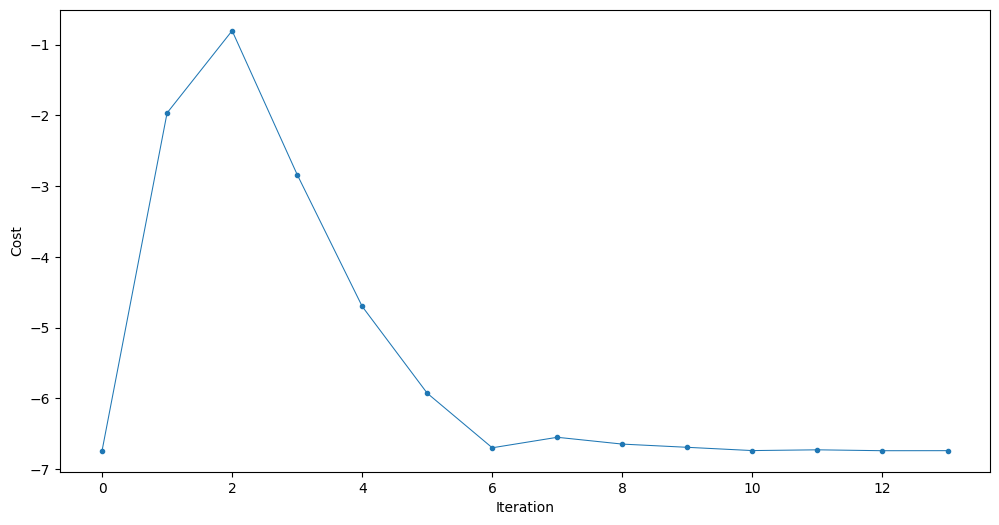

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(objective_func_vals,lw=0.75,marker='.')
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.show()


In [28]:

from qiskit_aer.primitives import SamplerV2 as Sampler

#  fixam seed-ul simulatorului pentru rezultate reproductibile
# la cele 10000 de masuratori, fara sa schimbam metoda de esantionare.
sampler = Sampler(default_shots=10000, seed=42)

pub = (candidate_circuit, result.x)
job = sampler.run([pub], shots=int(1e4))
counts_int = job.result()[0].data.meas.get_int_counts()
counts_bin = job.result()[0].data.meas.get_counts()
shots = sum(counts_int.values())
final_distribution_int = {key: val/shots for key, val in counts_int.items()}
final_distribution_bin = {key: val/shots for key, val in counts_bin.items()}
print(final_distribution_int)

{5: 0.6183, 4: 0.1211, 1: 0.042, 6: 0.1705, 2: 0.0111, 7: 0.027, 0: 0.0078, 3: 0.0022}


For the penalty value we tried 10,then 2 and finally we agreed on 12. Those earlier probability comparisons were produced with the previous QUBO formula, so they cannot be used to establish the performance of the corrected formulation. The value 12 equals the sum of the profits in our case. With the corrected QUBO, this penalty is sufficient to make the infeasible combinations less attractive, but it does not guarantee that QAOA will always sample the optimal solution.

**Aici am realizat ca:** A low probability of the valid bitstring 101 did not make that solution infeasible. The earlier phrase "worked perfectly" was not justified by the mathematical model or by a single run.

In [29]:
# auxiliary functions to sample most likely bitstring
def to_bitstring(integer, num_bits):
    result = np.binary_repr(integer, width=num_bits)
    return [int(digit) for digit in result]

keys = list(final_distribution_int.keys())
values = list(final_distribution_int.values())
most_likely = keys[np.argmax(np.abs(values))]
most_likely_bitstring = to_bitstring(most_likely, len(date_profituri))
most_likely_bitstring.reverse()

print("Result bitstring:", most_likely_bitstring)

#  verific daca rezultatul QAOA respecta bugetul si calculez profitul sau.
cost_rezultat = sum(c * bit for c, bit in zip(date_costuri, most_likely_bitstring))
profit_rezultat = sum(p * bit for p, bit in zip(date_profituri, most_likely_bitstring))
print("QAOA - cost:", cost_rezultat, "/ buget:", limita_buget)
print("QAOA - profit:", profit_rezultat)
print("QAOA - solutie fezabila:", cost_rezultat <= limita_buget)


from itertools import product
solutii_feza = [
    (list(bits), sum(p * bit for p, bit in zip(date_profituri, bits)))
    for bits in product((0, 1), repeat=len(date_profituri))
    if sum(c * bit for c, bit in zip(date_costuri, bits)) <= limita_buget
]
solutie_optima, profit_optim = max(solutii_feza, key=lambda x: x[1])
print("Optim clasic exact:", solutie_optima, "- profit:", profit_optim)
print("QAOA a identificat optimul:", most_likely_bitstring == solutie_optima)


Result bitstring: [1, 0, 1]
QAOA - cost: 3 / buget: 4
QAOA - profit: 8
QAOA - solutie fezabila: True
Optim clasic exact: [1, 0, 1] - profit: 8
QAOA a identificat optimul: True


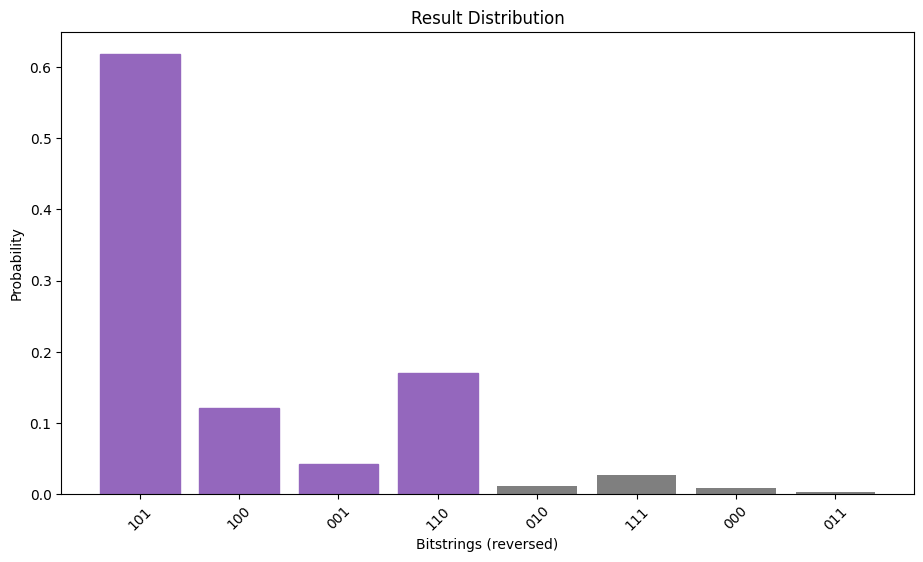

In [30]:
import matplotlib.pyplot as plt
import matplotlib

matplotlib.rcParams.update({"font.size": 10})
final_bits = final_distribution_bin
values = np.abs(np.array(list(final_bits.values()), dtype=float))
top_4_values = sorted(values, reverse=True)[:4]

fig, ax = plt.subplots(figsize=(11, 6))
plt.xticks(rotation=45)
ax.set_title("Result Distribution")
ax.set_xlabel("Bitstrings (reversed)")
ax.set_ylabel("Probability")

bars = ax.bar(list(final_bits.keys()), list(final_bits.values()), color="tab:grey")

for value in top_4_values:
    idxs = np.where(values == value)[0]   # array of indices
    for idx in idxs:                      # color all ties
        bars[int(idx)].set_color("tab:purple")

plt.show()

What resources and bibliography we used up until this point:
https://acrobat.adobe.com/id/urn:aaid:sc:DEU1:f397e09a-1cf8-4228-afd8-685b4377866b -our mathematical calculations to go from our calssical problem to QUBO form in a simplified way for a little example

https://colab.research.google.com/drive/1N1u0MO1IDy0c21Zg_oqioWSfabOxuiK6#scrollTo=9b99ce67-f121-4244-b62a-536be38fea86

https://colab.research.google.com/drive/1bZGXHaMb4EQytCQwbbRXEPzvzxdJy-U4

Gemini & Chat gpt to help us with the mathematical calculations and errors we made along the way


Why our solution is different to what the assignment asked?
The assignment gave us a number of railways and we had to find the best ways to use those railways to connect the number of given cities.
Example: Find the best way to connect 5 cities using 5 railways with a certain cost and profit by not going over your budget.

What we accidentaly did was actually ignore the number of given railways we had to build and we explored all the possible best solutions for building the railways such that we remain within our budget.
What this adds is that we check all the possibilities and we might even be able to create a complete graph if we do not go over our budget.
In our computation,we initially started with 3 qubits in order to better understand the problem. 3 qubits because we have 3 maximum railways we can build between 3 cities. That gives us all the states and they represent which railways out of the 3 we build.
So,for a number of 5 cities that we want to explore,we would need to use 10 qubits in order to visit the possibility of constructing all the railways(complete graph),because to us 1 qubit=1 railway.
That is why in pratice it is not possible at the moment to scale up to a larger number of cities to connect because that requires a huge number of qubits .
Even for 5 cities that would mean 10 railways=10 qubits in order to explore all the possible solutions and from our tests that means a very large hamiltonian matrix(1024x1024).You can see the result distribuition for 10 qubits below:

In [31]:

!pip -q install "qiskit[visualization]" qiskit-aer sympy numpy scipy matplotlib
import numpy as np
from qiskit.quantum_info import SparsePauliOp
from sympy import Matrix

print("REFORMULARE DIN QUBO ÎN HAMILTONIAN")

def construieste_hamiltonian_cale_ferata(profituri: list, costuri: list, buget: int, penalizare: float) -> list[tuple[str, float]]:
    n = len(profituri)
    lista_pauli = []
    matrice_q = np.zeros((n, n))

    # 1. Maximizarea profitului pe diagonală (în minimizare devine negativ)
    for i in range(n):
        matrice_q[i, i] = -profituri[i]


    if n != 10 or list(costuri) != [2, 3, 1, 1, 2, 2, 3 ,4 ,1 ,2] or buget != 7:
        raise ValueError("Penalizarea cu 3 qubiti este valida doar pentru costuri [2, 3, 1] si buget 4.")
    matrice_q[0, 1] += penalizare

    deplasare_constanta = 0.0
    coeficienti_liniari = np.zeros(n)
    coeficienti_patratici = np.zeros((n, n))

    # Transformarea din biți clasici x_i în operatori Pauli-Z: x_i = 0.5 - 0.5 * Z_i
    for i in range(n):
        valoare_q = matrice_q[i, i]
        deplasare_constanta += 0.5 * valoare_q
        coeficienti_liniari[i] -= 0.5 * valoare_q

    for i in range(n):
        for j in range(i + 1, n):
            valoare_q_ij = matrice_q[i, j] + matrice_q[j, i] # simetrizare
            if valoare_q_ij != 0:
                # x_i * x_j = 0.25 * (1 - Z_i - Z_j + Z_i Z_j)
                deplasare_constanta += 0.25 * valoare_q_ij
                coeficienti_liniari[i] -= 0.25 * valoare_q_ij
                coeficienti_liniari[j] -= 0.25 * valoare_q_ij
                coeficienti_patratici[i, j] = 0.25 * valoare_q_ij

    # Asamblarea listei finale de operatori Pauli
    lista_pauli.append(("I" * n, deplasare_constanta))

    for i in range(n):
        if coeficienti_liniari[i] != 0:
            operatori_pauli = ["I"] * n
            operatori_pauli[i] = "Z"
            lista_pauli.append(("".join(operatori_pauli)[::-1], coeficienti_liniari[i]))

    for i in range(n):
        for j in range(i + 1, n):
            if coeficienti_patratici[i, j] != 0:
                operatori_pauli = ["I"] * n
                operatori_pauli[i] = "Z"
                operatori_pauli[j] = "Z"
                lista_pauli.append(("".join(operatori_pauli)[::-1], coeficienti_patratici[i, j]))

    return lista_pauli

# Datele de intrare pentru problemă
date_profituri = [5, 4, 3, 1, 2, 3, 1, 2, 5, 3]       # Profitul pentru Șina 1, 2, 3
date_costuri = [2, 3, 1, 1, 2, 2, 3 ,4 ,1 ,2]         # Costul pentru Șina 1, 2, 3
limita_buget = 7                 # Bugetul maxim admis
factor_penalizare =29.0      # Factorul de penalizare P

# Generarea Hamiltonianului de Cost
elemente_pauli_cale_ferata = construieste_hamiltonian_cale_ferata(date_profituri, date_costuri, limita_buget, factor_penalizare)
hamiltonian_cost = SparsePauliOp.from_list(elemente_pauli_cale_ferata)

print("Hamiltonianul Funcției de Cost (Generat din funcția tradusă):")
print(hamiltonian_cost)

#display(Matrix(hamiltonian_cost.to_matrix()))
#display('Diagonal', Matrix(np.diag(hamiltonian_cost.to_matrix())))

REFORMULARE DIN QUBO ÎN HAMILTONIAN
Hamiltonianul Funcției de Cost (Generat din funcția tradusă):
SparsePauliOp(['IIIIIIIIII', 'IIIIIIIIIZ', 'IIIIIIIIZI', 'IIIIIIIZII', 'IIIIIIZIII', 'IIIIIZIIII', 'IIIIZIIIII', 'IIIZIIIIII', 'IIZIIIIIII', 'IZIIIIIIII', 'ZIIIIIIIII', 'IIIIIIIIZZ'],
              coeffs=[-7.25+0.j, -4.75+0.j, -5.25+0.j,  1.5 +0.j,  0.5 +0.j,  1.  +0.j,
  1.5 +0.j,  0.5 +0.j,  1.  +0.j,  2.5 +0.j,  1.5 +0.j,  7.25+0.j])


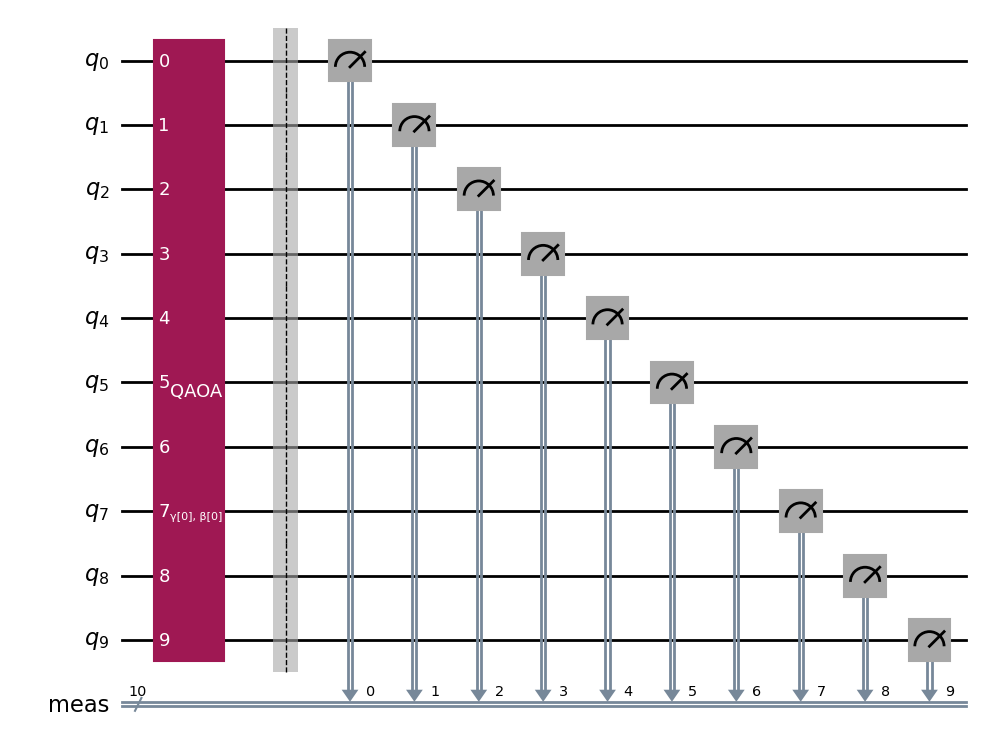

In [32]:
from qiskit.circuit.library import QAOAAnsatz
!pip install qiskit[visualization]
circuit = QAOAAnsatz(cost_operator=hamiltonian_cost, reps=1)
circuit.measure_all()

circuit.draw('mpl')

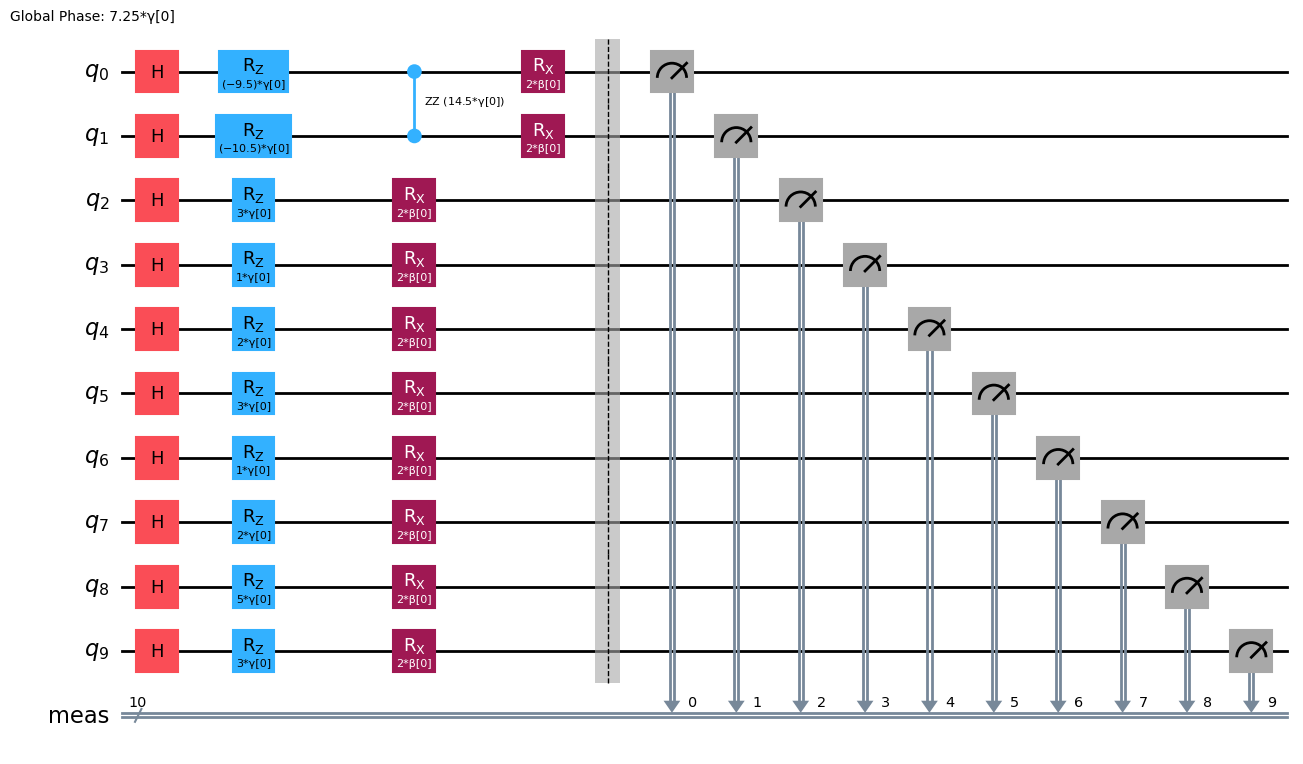

In [33]:
from qiskit_aer import AerSimulator
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

backend = AerSimulator()

pm = generate_preset_pass_manager(optimization_level=3,
                                    backend=backend,
                                    seed_transpiler=42)

candidate_circuit = pm.run(circuit)
candidate_circuit.draw('mpl', fold=False, idle_wires=False)

In [34]:

assert candidate_circuit.num_parameters == 2, "Acest proiect foloseste QAOA cu reps=1 (doi parametri)."
init_params = [0.90, 3.82]


In [35]:
def cost_func_estimator(params, ansatz, hamiltonian, estimator):

    # transform the observable defined on virtual qubits to
    # an observable defined on all physical qubits

    ansatz_fara_masuratori = ansatz.remove_final_measurements(inplace=False)
    isa_hamiltonian = hamiltonian.apply_layout(ansatz.layout)

    pub = (ansatz_fara_masuratori, isa_hamiltonian, params)
    job = estimator.run([pub])

    results = job.result()[0]

    cost = float(np.asarray(results.data.evs).item())

    objective_func_vals.append(cost)


    return cost

In [36]:

from qiskit_aer.primitives import EstimatorV2 as Estimator
from scipy.optimize import minimize

objective_func_vals = [] # Global variable
estimator = Estimator()

result = minimize(
    cost_func_estimator,
    init_params,
    args=(candidate_circuit, hamiltonian_cost, estimator),
    method="COBYLA",
    options={
        "maxiter": 30,
        "tol": 1e-2,
    },
)
print(result)


 message: Return from COBYLA because the trust region radius reaches its lower bound.
 success: True
  status: 0
     fun: -17.837012634223708
       x: [ 9.033e-01  3.741e+00]
    nfev: 21
   maxcv: 0.0


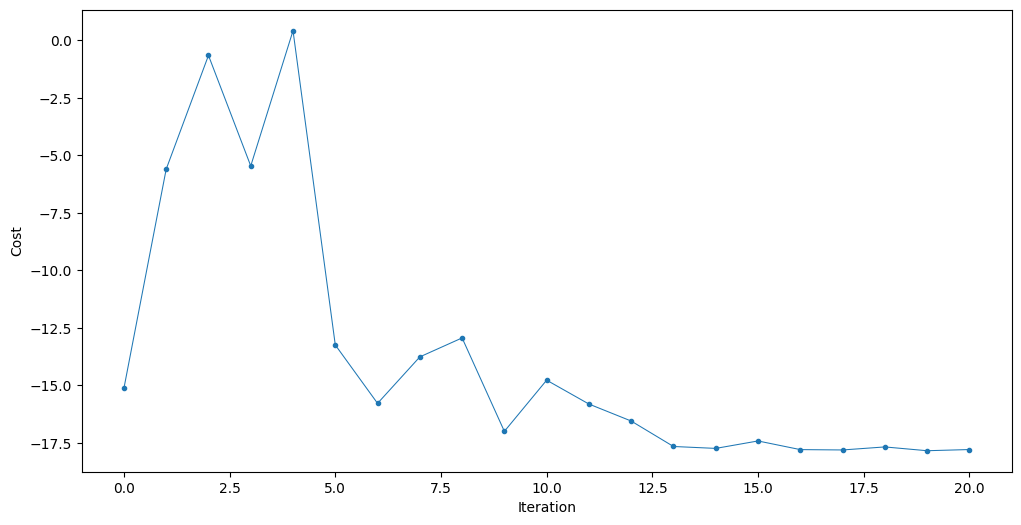

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(objective_func_vals,lw=0.75,marker='.')
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.show()


In [38]:

from qiskit_aer.primitives import SamplerV2 as Sampler


sampler = Sampler(default_shots=10000, seed=42)

pub = (candidate_circuit, result.x)
job = sampler.run([pub], shots=int(1e4))
counts_int = job.result()[0].data.meas.get_int_counts()
counts_bin = job.result()[0].data.meas.get_counts()
shots = sum(counts_int.values())
final_distribution_int = {key: val/shots for key, val in counts_int.items()}
final_distribution_bin = {key: val/shots for key, val in counts_bin.items()}
print(final_distribution_int)

{813: 0.0679, 621: 0.1599, 877: 0.2243, 557: 0.0503, 622: 0.0363, 876: 0.0164, 525: 0.0012, 869: 0.0691, 885: 0.0028, 550: 0.0034, 765: 0.0006, 878: 0.0488, 805: 0.0183, 549: 0.0146, 893: 0.0093, 613: 0.0467, 614: 0.0097, 933: 0.001, 741: 0.0023, 1005: 0.0117, 865: 0.0018, 620: 0.0137, 781: 0.0024, 357: 0.0015, 1006: 0.0022, 806: 0.0042, 556: 0.003, 628: 0.0002, 629: 0.0028, 881: 0.0003, 829: 0.0037, 717: 0.0003, 868: 0.0044, 998: 0.0006, 558: 0.01, 870: 0.0162, 109: 0.0049, 814: 0.0122, 638: 0.0016, 997: 0.0034, 637: 0.0082, 365: 0.0056, 845: 0.0054, 941: 0.0023, 612: 0.004, 973: 0.0002, 821: 0.0011, 518: 0.0001, 590: 0.0007, 742: 0.0003, 589: 0.0056, 894: 0.0022, 1001: 0.0005, 873: 0.0049, 750: 0.0011, 609: 0.0009, 749: 0.0082, 874: 0.0013, 581: 0.0014, 616: 0.0003, 886: 0.0007, 356: 0.0004, 366: 0.0012, 822: 0.0002, 301: 0.0019, 617: 0.0042, 804: 0.0011, 902: 0.0001, 618: 0.0012, 633: 0.0003, 294: 0.0002, 837: 0.0021, 362: 0.0001, 778: 0.0001, 993: 0.0003, 748: 0.0006, 573: 0.0023, 

In [39]:
# auxiliary functions to sample most likely bitstring
def to_bitstring(integer, num_bits):
    result = np.binary_repr(integer, width=num_bits)
    return [int(digit) for digit in result]

keys = list(final_distribution_int.keys())
values = list(final_distribution_int.values())
most_likely = keys[np.argmax(np.abs(values))]
most_likely_bitstring = to_bitstring(most_likely, len(date_profituri))
most_likely_bitstring.reverse()

print("Result bitstring:", most_likely_bitstring)


cost_rezultat = sum(c * bit for c, bit in zip(date_costuri, most_likely_bitstring))
profit_rezultat = sum(p * bit for p, bit in zip(date_profituri, most_likely_bitstring))
print("QAOA - cost:", cost_rezultat, "/ buget:", limita_buget)
print("QAOA - profit:", profit_rezultat)
print("QAOA - solutie fezabila:", cost_rezultat <= limita_buget)


from itertools import product
solutii_feza = [
    (list(bits), sum(p * bit for p, bit in zip(date_profituri, bits)))
    for bits in product((0, 1), repeat=len(date_profituri))
    if sum(c * bit for c, bit in zip(date_costuri, bits)) <= limita_buget
]
solutie_optima, profit_optim = max(solutii_feza, key=lambda x: x[1])
print("Optim clasic exact:", solutie_optima, "- profit:", profit_optim)
print("QAOA a identificat optimul:", most_likely_bitstring == solutie_optima)


Result bitstring: [1, 0, 1, 1, 0, 1, 1, 0, 1, 1]
QAOA - cost: 12 / buget: 7
QAOA - profit: 21
QAOA - solutie fezabila: False
Optim clasic exact: [1, 0, 1, 1, 0, 0, 0, 0, 1, 1] - profit: 17
QAOA a identificat optimul: False


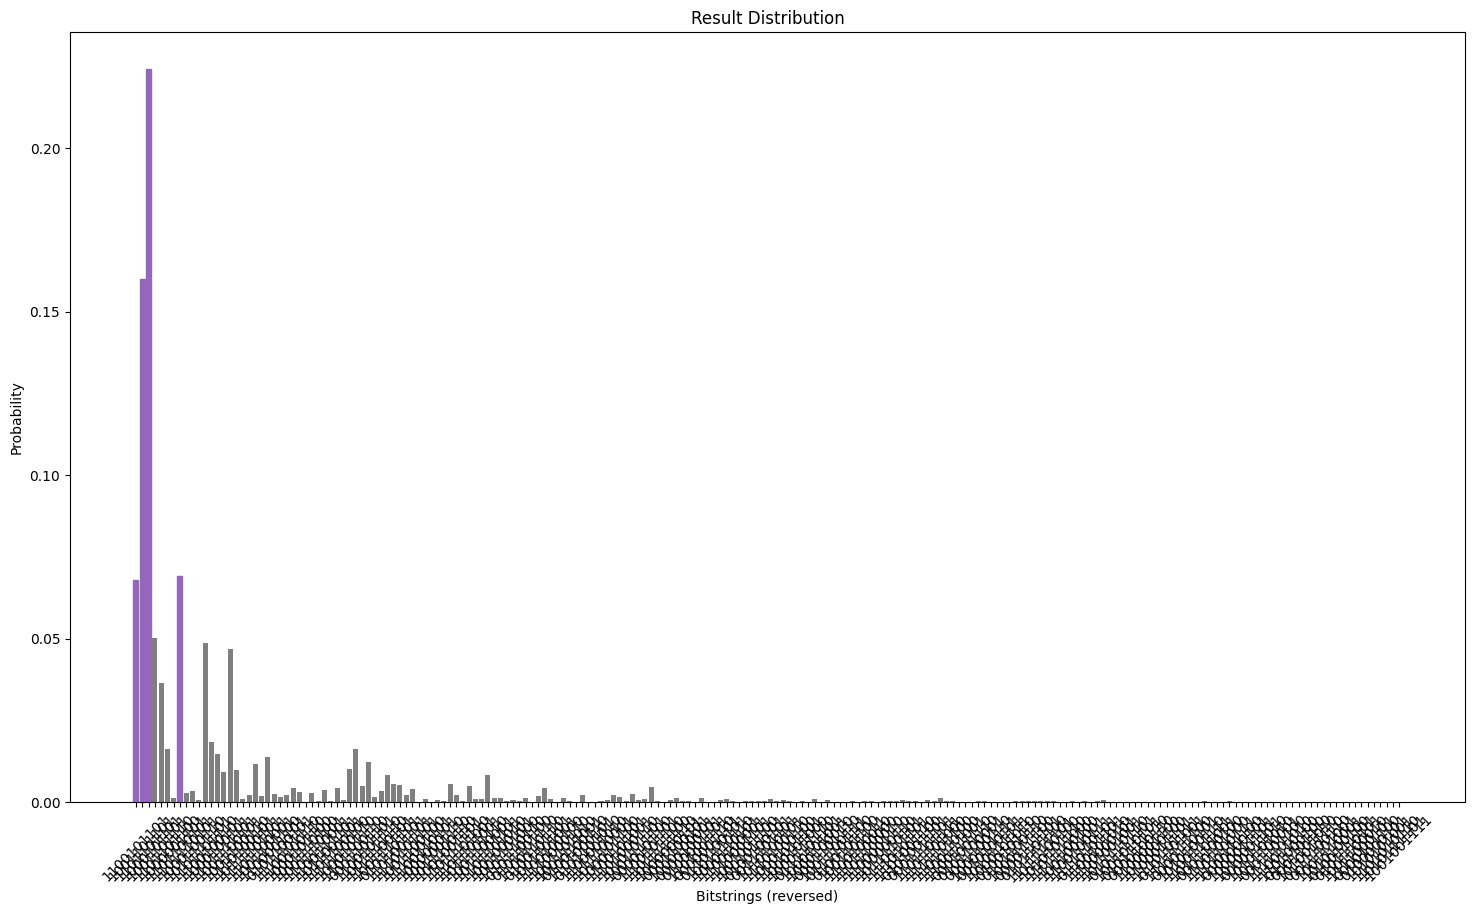

In [40]:
import matplotlib.pyplot as plt
import matplotlib

matplotlib.rcParams.update({"font.size": 10})
final_bits = final_distribution_bin
values = np.abs(np.array(list(final_bits.values()), dtype=float))
top_4_values = sorted(values, reverse=True)[:4]

fig, ax = plt.subplots(figsize=(18, 10))
plt.xticks(rotation=45)
ax.set_title("Result Distribution")
ax.set_xlabel("Bitstrings (reversed)")
ax.set_ylabel("Probability")

bars = ax.bar(list(final_bits.keys()), list(final_bits.values()), color="tab:grey")

for value in top_4_values:
    idxs = np.where(values == value)[0]   # array of indices
    for idx in idxs:                      # color all ties
        bars[int(idx)].set_color("tab:purple")

plt.show()

This is the way we classically approached the solution of the problem and we ended up with the following results:
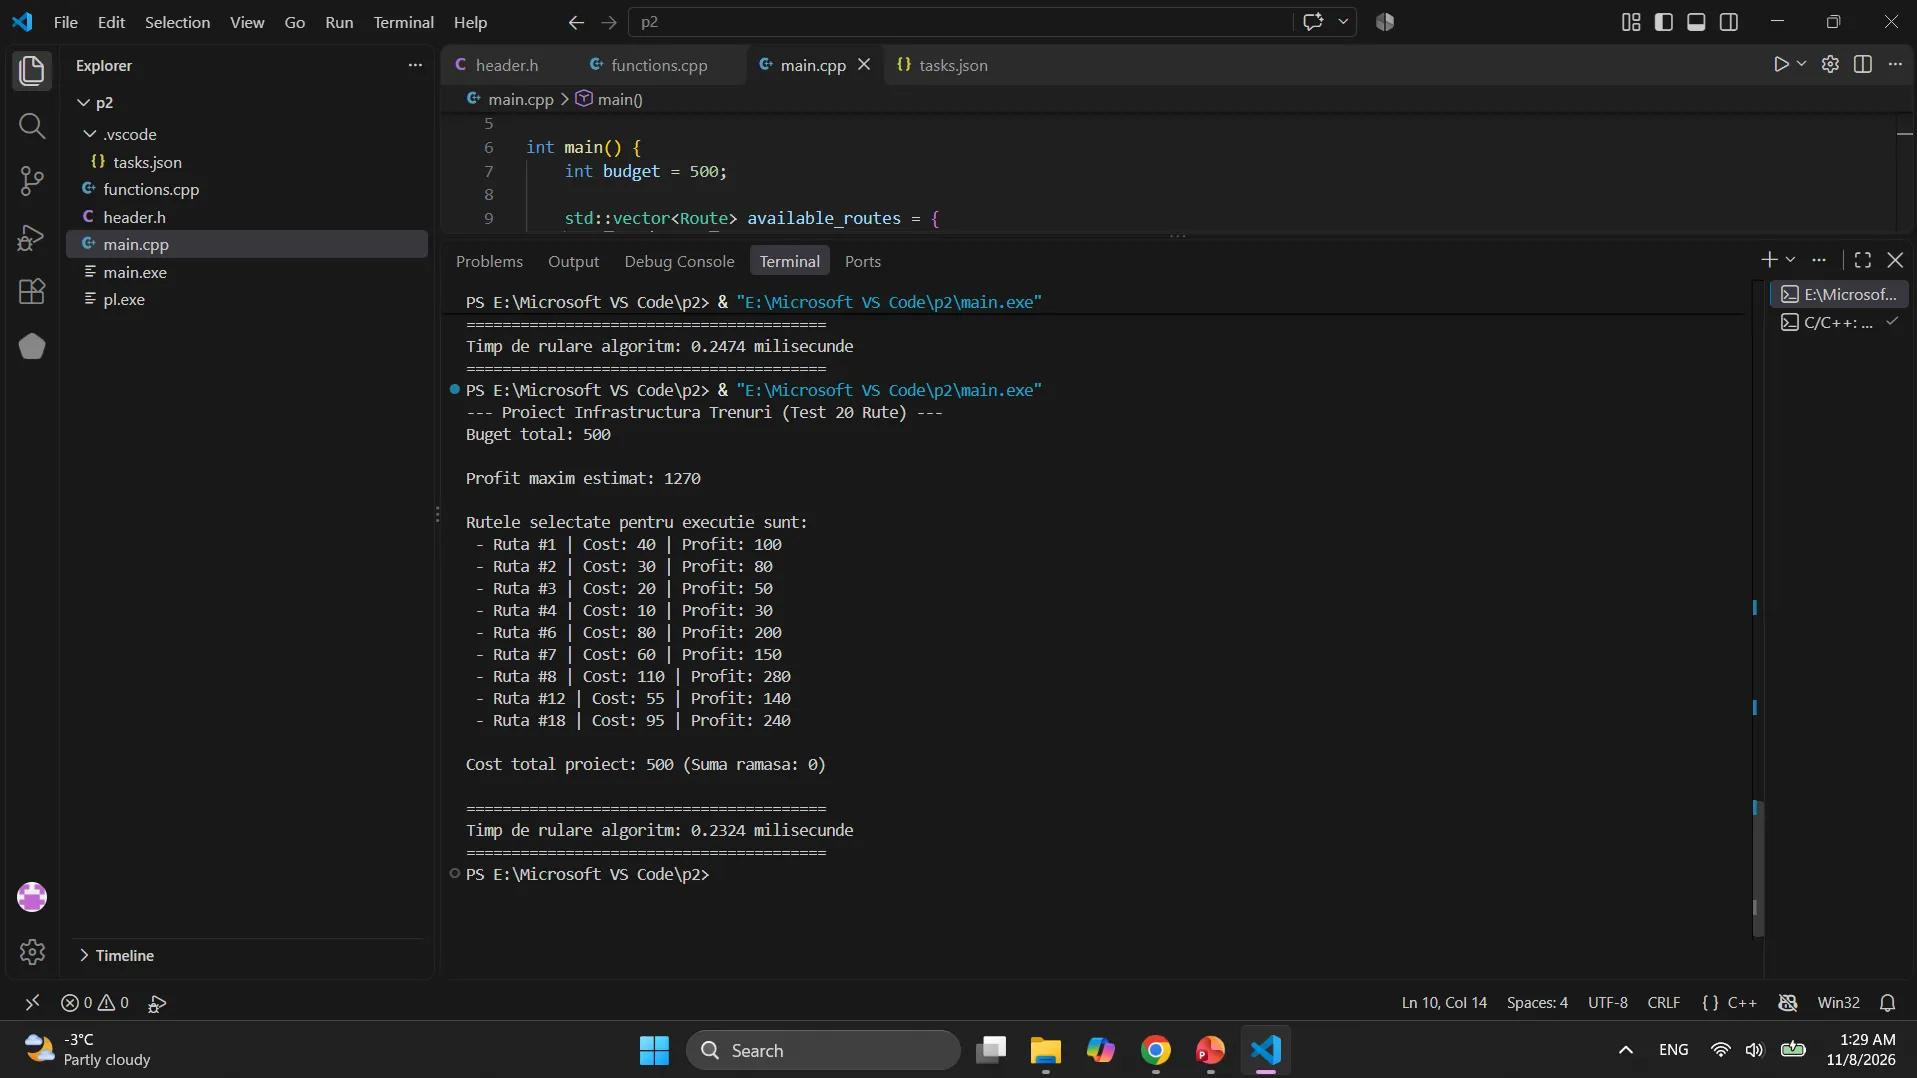